<a href="https://colab.research.google.com/github/Saransh-Basu-01/50-Ml-Projects-to-understand-LLMs/blob/main/Project_30_Sentiment_Analysis_with_Decision_Trees.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:

import numpy as np
import matplotlib.pyplot as plt

import torch

from tqdm import tqdm
from scipy.stats import ttest_ind

from sklearn.tree import DecisionTreeClassifier
from sklearn.decomposition import PCA
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression

from transformers import BertTokenizer, BertModel
from datasets import load_dataset

# Part_1:Import Bert and Dataset

## Task_1:
- Import BERT-large and engage the output_hidden_states setting.
Move the model to the GPU if available. Import a piece of the
“SST2” dataset using the following code:
load_dataset(’glue’,’sst2’,split=’train[:5%]’)
Inspect the dataset to understand its organization. Create a
list variable that contains the data labels, and report the number
and percent of occurrences of each label type.

In [2]:
tokenizer = BertTokenizer.from_pretrained('bert-large-uncased')
model = BertModel.from_pretrained('bert-large-uncased', output_hidden_states=True)
model.eval()

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

config.json:   0%|          | 0.00/571 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 1.34GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/391 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: bert-large-uncased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


BertModel(
  (embeddings): BertEmbeddings(
    (word_embeddings): Embedding(30522, 1024, padding_idx=0)
    (position_embeddings): Embedding(512, 1024)
    (token_type_embeddings): Embedding(2, 1024)
    (LayerNorm): LayerNorm((1024,), eps=1e-12, elementwise_affine=True, bias=True)
    (dropout): Dropout(p=0.1, inplace=False)
  )
  (encoder): BertEncoder(
    (layer): ModuleList(
      (0-23): 24 x BertLayer(
        (attention): BertAttention(
          (self): BertSelfAttention(
            (query): Linear(in_features=1024, out_features=1024, bias=True)
            (key): Linear(in_features=1024, out_features=1024, bias=True)
            (value): Linear(in_features=1024, out_features=1024, bias=True)
            (dropout): Dropout(p=0.1, inplace=False)
          )
          (output): BertSelfOutput(
            (dense): Linear(in_features=1024, out_features=1024, bias=True)
            (LayerNorm): LayerNorm((1024,), eps=1e-12, elementwise_affine=True, bias=True)
            (dropout

In [3]:
model.config

BertConfig {
  "add_cross_attention": false,
  "architectures": [
    "BertForMaskedLM"
  ],
  "attention_probs_dropout_prob": 0.1,
  "bos_token_id": null,
  "classifier_dropout": null,
  "dtype": "float32",
  "eos_token_id": null,
  "gradient_checkpointing": false,
  "hidden_act": "gelu",
  "hidden_dropout_prob": 0.1,
  "hidden_size": 1024,
  "initializer_range": 0.02,
  "intermediate_size": 4096,
  "is_decoder": false,
  "layer_norm_eps": 1e-12,
  "max_position_embeddings": 512,
  "model_type": "bert",
  "num_attention_heads": 16,
  "num_hidden_layers": 24,
  "output_hidden_states": true,
  "pad_token_id": 0,
  "position_embedding_type": "absolute",
  "tie_word_embeddings": true,
  "transformers_version": "5.22.1",
  "type_vocab_size": 2,
  "use_cache": true,
  "vocab_size": 30522
}

In [4]:

# move the model to the GPU
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
model.to(device);


In [5]:
device

device(type='cuda')

In [6]:
dataset = load_dataset('gimmaru/glue-sst2',split='validation')

dataset

README.md:   0%|          | 0.00/775 [00:00<?, ?B/s]

data/validation-00000-of-00001-02c8af09f(…): reconstructing file:   0%|          |  0.00B / 72.7kB            

data/validation-00000-of-00001-02c8af09f(…): downloading bytes:           |  0.00B            

Generating validation split:   0%|          | 0/872 [00:00<?, ? examples/s]

Dataset({
    features: ['sentence', 'label', 'idx'],
    num_rows: 872
})

In [7]:
dataset[123]

{'sentence': 'this piece of channel 5 grade trash is , quite frankly , an insult to the intelligence of the true genre enthusiast . ',
 'label': 0,
 'idx': 814}

In [13]:
np.unique(dataset['label'],return_counts=True)

(array([0, 1]), array([428, 444]))

In [11]:

# extract and count the labels
labels = [sample['label'] for sample in dataset]

num_samples = len(labels)

uniq,counts = np.unique(labels,return_counts=True)
for u,c in zip(uniq,counts):
  print(f'"{u}" appeared {c} times ({c/num_samples:.1%}).')


"0" appeared 428 times (49.1%).
"1" appeared 444 times (50.9%).


# Part_2:Create Batches

## Task_1:
- Given a batch size of 32 and a sample size of 3367 (this is the num
ber of data samples, not the number of tokens), calculate how many
batches can be created, and how many total samples will be contained
across all batches

In [18]:
batchsize = 32
num_batch=num_samples//batchsize
sample_size =batchsize * num_batch

print(f'There are {num_batch} batches of size {batchsize}, leading to {sample_size} total samples.')

There are 27 batches of size 32, leading to 864 total samples.


In [16]:
len(dataset)

872

## Task_2:
- Initialize two empty Python lists, one for the batches and one for the
labels. Then create a for-loop over the number of batches.
Find the start and end indices into the dataset for each batch.
Initialize temporary lists for the texts (sentence key) and labels.
Append 32 sequential text samples. Tokenize that list of texts and
store as a new element in the all-batches list. The sentences have
differing lengths, so make sure to tokenize with padding.
After creating the two lists, confirm the following sizes: the
all-labels and all-batches lists each contain 105 elements; each labels
element contains 32 numbers; each all-batches element should be a
tokenizer dictionary containing token IDs and the attention mask.
The sizes of the batches will vary depending on the sentences therein,
so you can extract the number of sequences, and the sequence length,
for each of 105 batches and visualize as in Figure 5.39.
Finally, run one batch through the LLM to check the sizes of
the hidden-state tensors. For example, batch 10 should produce
hidden-state vectors of size 32 × 38 × 1024.

In [19]:

allbatches = []
alllabels = []

for batchi in range(num_batch):

  # start and end indices
  startidx =batchi * batchsize
  endidx = startidx + batchsize

  # append texts
  tmp_texts = []
  tmp_labels = []
  for samplei in range(startidx,endidx):
    tmp_texts.append(dataset[samplei]['sentence'])
    tmp_labels.append(dataset[samplei]['label'])

  # tokenize
  tokens = tokenizer(tmp_texts,return_tensors='pt',padding=True)
  allbatches.append(tokens)
  alllabels.append(tmp_labels)

In [27]:
len(allbatches),len(alllabels)

(27, 27)

In [30]:
len(alllabels[10])

32

In [37]:
allbatches[0]['input_ids'][0]

tensor([  101,  2009,  4152,  3031,  1996,  3898,  2074,  2055,  2004,  2172,
         1997,  1996, 20674,  2004,  2028,  2071, 16286,  5987,  1010,  1998,
         2003, 25540, 25725,  2075,  1998,  3048,  1999,  2049,  2219,  2157,
         1012,   102,     0,     0,     0,     0,     0,     0,     0,     0,
            0,     0,     0,     0,     0,     0,     0,     0,     0])

In [35]:
dataset[0]

{'sentence': 'it gets onto the screen just about as much of the novella as one could reasonably expect , and is engrossing and moving in its own right . ',
 'label': 1,
 'idx': 726}

In [39]:
tokenizer.decode(allbatches[0]['input_ids'][0])

'[CLS] it gets onto the screen just about as much of the novella as one could reasonably expect, and is engrossing and moving in its own right. [SEP] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD]'

In [28]:


len(alllabels[10]), allbatches[10], allbatches[10]['input_ids'].shape

(32,
 {'input_ids': tensor([[ 101, 9020, 2000,  ...,    0,    0,    0],
         [ 101, 2009, 2003,  ...,    0,    0,    0],
         [ 101, 1037, 2143,  ...,    0,    0,    0],
         ...,
         [ 101, 2054, 1005,  ...,    0,    0,    0],
         [ 101, 2130, 2006,  ...,    0,    0,    0],
         [ 101, 5001, 8490,  ...,    0,    0,    0]]), 'token_type_ids': tensor([[0, 0, 0,  ..., 0, 0, 0],
         [0, 0, 0,  ..., 0, 0, 0],
         [0, 0, 0,  ..., 0, 0, 0],
         ...,
         [0, 0, 0,  ..., 0, 0, 0],
         [0, 0, 0,  ..., 0, 0, 0],
         [0, 0, 0,  ..., 0, 0, 0]]), 'attention_mask': tensor([[1, 1, 1,  ..., 0, 0, 0],
         [1, 1, 1,  ..., 0, 0, 0],
         [1, 1, 1,  ..., 0, 0, 0],
         ...,
         [1, 1, 1,  ..., 0, 0, 0],
         [1, 1, 1,  ..., 0, 0, 0],
         [1, 1, 1,  ..., 0, 0, 0]])},
 torch.Size([32, 50]))

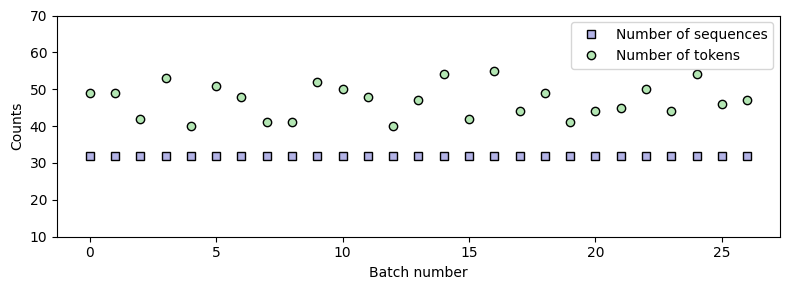

In [31]:
# lengths of different batches
seqlens = [allbatches[i]['input_ids'].shape[1] for i in range(len(allbatches))]
numseqs = [allbatches[i]['input_ids'].shape[0] for i in range(len(allbatches))]

plt.figure(figsize=(8,3))
plt.plot(numseqs,'ks',markerfacecolor=[.7,.7,.9],label='Number of sequences')
plt.plot(seqlens,'ko',markerfacecolor=[.7,.9,.7],label='Number of tokens')
plt.gca().set(xlabel='Batch number',ylabel='Counts',ylim=[10,70])
plt.legend()

plt.tight_layout()
plt.show()

In [32]:
outputs = model(**allbatches[10].to(device))
outputs.hidden_states[4].shape

torch.Size([32, 50, 1024])

# Part 3: Get the [CLS] hidden state activations from one layer

## Task_1:
- In a for-loop over the batches, run a forward pass on each batch.
Extract the hidden states from the first token in the final hidden
layer, bring it back to the CPU and convert it to a NumPy array.
Combine all the activations into a 3360 × 1024 matrix, and all the
labels into a 3360 dimensionless array.

In [40]:

# this code block takes a very long time on a standard CPU, ~5 mins on a high-power CPU, and a few seconds on a GPU
cls_activations = []

for batchi in tqdm(range(num_batch)):

  # run the model
  outputs = model(**allbatches[batchi].to(device))

  # extract the CLS activation from the hidden states
  cls_batch =outputs.hidden_states[-1][:,0,:].detach().cpu().numpy()

  # append to a list
  cls_activations.append(cls_batch)

# and convert to numpy
cls_activations = np.vstack(cls_activations)
labels = np.hstack(alllabels)

cls_activations.shape, labels.shape

100%|██████████| 27/27 [00:07<00:00,  3.85it/s]


((864, 1024), (864,))

## Task_2:
- Examine whether the vector average differentiates the two categories,
by averaging the hidden-state vectors to get one number per sam
ple. Perform an independent-samples t-test to determine whether
the vector average predicts category label, using the SciPy function
ttest_ind. Visualize the data and t-test result using violin plots as
in Figure 5.40.

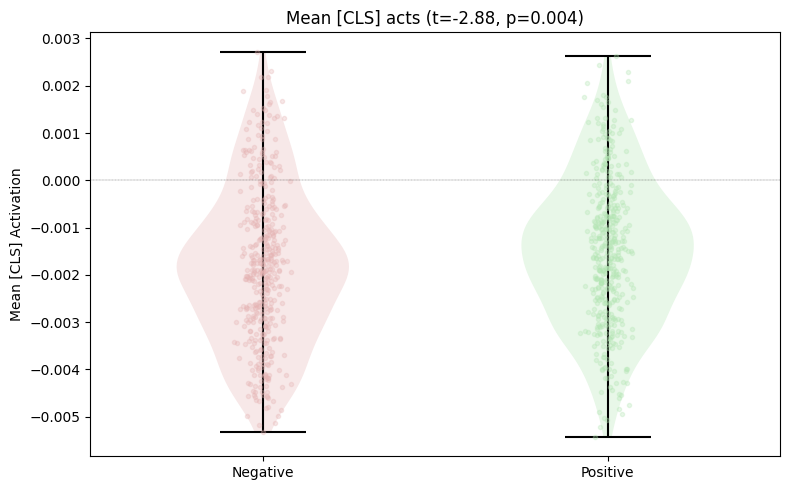

In [46]:
acts0 = cls_activations[labels==0,:].mean(axis=1)
acts1 = cls_activations[labels==1,:].mean(axis=1)

# t-test
t = ttest_ind(acts0,acts1)

# the violin plot
plt.figure(figsize=(8,5))
v = plt.violinplot([acts0,acts1])

# change the colors
v['bodies'][0].set_facecolor([.9,.7,.7])
v['bodies'][1].set_facecolor([.7,.9,.7])
v['cbars'].set_edgecolor('k')
v['cmins'].set_edgecolor('k')
v['cmaxes'].set_edgecolor('k')

# draw all the dots
plt.plot(np.random.normal(1,.03,len(acts0)),acts0,'.',color=[.9,.7,.7,.3])
plt.plot(np.random.normal(2,.03,len(acts1)),acts1,'.',color=[.7,.9,.7,.3])

# and finishing touches
plt.axhline(0,linestyle='--',linewidth=.2,color='k')
plt.gca().set(xticks=[1,2],xticklabels=['Negative','Positive'],ylabel='Mean [CLS] Activation',
              xlim=[.5,2.5],title=f'Mean [CLS] acts (t={t.statistic:.2f}, p={t.pvalue:.3f})')

plt.tight_layout()
plt.show()

# Part 4: Single-layer decision-tree classifier

## Task_1:
- Fit a PCA on the CLS activations matrix. Keep the number of
components that accounts for 80% of the total variance. Obtain the
PCA scores for those components via the fit_transform method.
Print the number of components and variance explained, and the
ratio of observations to features.
Train
a
Use the scikit-learn function train_test_split to separate
the data into train (80%) and test (20%) sets. Use the stratify
input argument to ensure that the train and test splits have the
same ratio of categories.
decision-tree
classifier
using
the
function
DecisionTreeClassifier. Set the max_depth parameter to 4.
Fit the model on the training data, and calculate both train and test
accuracy

In [47]:

# dimension reduction with pca
pca = PCA(n_components=.8)
act_reduced = pca.fit_transform(cls_activations)

print(f'Kept {pca.n_components_} components explaining {pca.explained_variance_ratio_.sum():.2%} variance.\n')
print(f'Original data size is {cls_activations.shape}')
print(f' Reduced data size is {act_reduced.shape}\n')
print(f'Observations:features ratio is {act_reduced.shape[0]}:{act_reduced.shape[1]} = {act_reduced.shape[0]/act_reduced.shape[1]:.1f}')


# split the data into train and test
X_train,X_test, y_train,y_test = train_test_split(act_reduced,labels,test_size=.2,stratify=labels)
dectree = DecisionTreeClassifier(max_depth=4)
dectree.fit(X_train, y_train)

# train and test accuracy
train_acc = (dectree.predict(X_train) == y_train).mean()
test_acc  = (dectree.predict(X_test) == y_test).mean()

print(f'Accuracies: Train {train_acc:.2%}, Test: {test_acc:.2%}')

Kept 114 components explaining 80.10% variance.

Original data size is (864, 1024)
 Reduced data size is (864, 114)

Observations:features ratio is 864:114 = 7.6
Accuracies: Train 86.11%, Test: 79.19%
